# Phân tích thống kê để chọn feature dự đoán giá thuê (Đà Nẵng)

**Mục tiêu:** dùng T-test, ANOVA, ma trận tương quan (kèm vài kiểm định bổ trợ) để quyết định feature nào đưa vào
- **mô hình tuyến tính** (Ridge/Lasso/ElasticNet) và
- **mô hình phi tuyến** (HistGradientBoosting...).

**Quy trình**

| Bước | Nội dung | Trả lời câu hỏi |
|---|---|---|
| 1 | Cấu hình, nạp & làm sạch dữ liệu | Dữ liệu sạch giống script train? |
| 2 | Kiểm tra chất lượng cột (hằng số, rò rỉ nhãn) | Cột nào vô dụng / gian lận? |
| 3 | Phân phối biến mục tiêu | Vì sao dùng `log(price)`? |
| 4 | Tương quan Pearson/Spearman, đa cộng tuyến, VIF | Biến số nào liên quan tới giá, cặp nào trùng thông tin? |
| 5 | T-test (Welch) + Mann-Whitney + Cohen's d | Biến nhị phân (0/1) có làm giá khác biệt? |
| 6 | ANOVA / Welch-ANOVA / Kruskal + η² + Tukey + Cramér's V | Biến phân loại có làm giá khác biệt? |
| 7 | Mutual Information (có noise baseline) | Quan hệ phi tuyến mà tương quan bỏ sót? |
| 8 | Kiểm định riêng phần (partial F-test, OLS) | Sau khi kiểm soát các biến khác, biến còn đóng góp không? |
| 9 | Bảng tổng hợp & quyết định chọn feature | Danh sách feature cuối cùng |
| 10 | Kiểm chứng bằng cross-validation | Chọn feature có làm mô hình tệ đi không? |

> **Lưu ý quan trọng:** với n ≈ vài nghìn mẫu, p-value gần như luôn rất nhỏ. Vì vậy mỗi kiểm định đều đi kèm **effect size**
> (Cohen's d, η², |ρ|) và hiệu chỉnh **đa kiểm định (FDR Benjamini-Hochberg)** — *ý nghĩa thống kê ≠ ý nghĩa thực tiễn*.

## 1. Cấu hình & nạp dữ liệu

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", font_scale=0.95)

# ===================== CẤU HÌNH =====================
CSV_PATH = "rental_room_rows.csv"
CATEGORY = "Phòng trọ"            # "Phòng trọ"  hoặc  "Căn hộ/Chung cư"  (chạy lại notebook cho từng loại)

# Cùng quy tắc lọc như train_tro.py / train_canho.py
PRESETS = {
    "Phòng trọ":        dict(years=[2025, 2026], exclude_wards=["Hải Vân"], merge_unknown_furn=True),
    "Căn hộ/Chung cư":  dict(years=[2026],       exclude_wards=[],          merge_unknown_furn=False),
}
CFG = PRESETS[CATEGORY]

ALPHA = 0.05            # mức ý nghĩa cho kiểm định đơn biến (p đã hiệu chỉnh FDR)
PARTIAL_ALPHA = 0.10    # ngưỡng GIỮ lại ở kiểm định riêng phần (thoáng hơn, như p-to-enter trong chọn biến)
IQR_K = 1.5             # ngưỡng loại outlier (giống script train)
MIN_GROUP = 30          # nhóm nhị phân nhỏ hơn số này -> không đủ tin cậy để test
MIN_GROUP_CAT = 10      # nhóm phân loại nhỏ hơn số này -> bỏ khỏi ANOVA
CORR_THRESH = 0.80      # |ρ| giữa 2 biến vượt ngưỡng -> coi là dư thừa
MIN_EFFECT = dict(d=0.20, eta2=0.01, rho=0.10)   # ngưỡng "effect nhỏ" theo Cohen
RANDOM_STATE = 42
TARGET = "log_price"

In [2]:
raw = pd.read_csv(CSV_PATH)
df = raw[raw["category_name"] == CATEGORY].copy()
n_cat = len(df)

df["posted_date"] = pd.to_datetime(df["posted_date"], format="mixed")
df = df[df["posted_date"].dt.year.isin(CFG["years"])].copy()
n_year = len(df)

if CFG["exclude_wards"]:
    df = df[~df["ward_name"].isin(CFG["exclude_wards"])]

if CFG["merge_unknown_furn"]:
    df["furnishing_status"] = df["furnishing_status"].replace("Không xác định", "Không nội thất")

df = df.drop_duplicates(["latitude", "longitude", "price_vnd", "size_m2", "furnishing_status", "rooms"])
n_dedup = len(df)

df[TARGET] = np.log(df["price_vnd"])

def iqr_mask(s, k=IQR_K):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return s.between(q1 - k * iqr, q3 + k * iqr)

df = df[iqr_mask(df[TARGET]) & iqr_mask(df["size_m2"])].reset_index(drop=True)

print(f"{CATEGORY}: {n_cat} -> năm {CFG['years']}: {n_year} -> bỏ trùng: {n_dedup} -> bỏ outlier IQR: {len(df)}")
print(f"Giá: {df.price_vnd.min():,.0f} - {df.price_vnd.max():,.0f} VND | Diện tích: {df.size_m2.min():.0f} - {df.size_m2.max():.0f} m2")
df.head()

Phòng trọ: 1894 -> năm [2025, 2026]: 1374 -> bỏ trùng: 1293 -> bỏ outlier IQR: 1190
Giá: 1,100,000 - 8,500,000 VND | Diện tích: 10 - 45 m2


,source,list_id,posted_date,price_vnd,size_m2,price_per_m2_vnd,furnishing_status,rooms,category_name,latitude,longitude,ward_name,dist_to_cbd,dist_to_beach,nearest_beach_code,dist_to_airport,dist_to_nearest_uni,nearest_uni_code,flooded_2022,flooded_2025,flood_risk_label,has_balcony,free_hours,has_camera_security,has_elevator,has_mezzanine,private_bathroom,wifi,has_parking,has_window,log_price
0,nhatot_phongtro,129354389,2026-10-08,2500000,16.0000,156250,Không nội thất,1,Phòng trọ,16.0888,108.2171,Hải Châu,3.1520,2.4610,ThanhBinh,5.3360,1.2830,VNUK,False,False,0,0,1,0,0,0,0,0,0,0,14.7318
1,nhatot_phongtro,130783616,2026-09-18,3300000,25.0000,132000,Đầy đủ nội thất,1,Phòng trọ,15.9924,108.2110,Hòa Xuân,7.7340,6.1350,SonThuy,5.8590,4.4910,UFLS,False,False,0,0,0,1,0,0,0,1,1,0,15.0094
2,nhatot_phongtro,130995112,2026-09-25,4500000,35.0000,128571,Đầy đủ nội thất,1,Phòng trọ,15.9769,108.2604,Ngũ Hành Sơn,10.1750,2.2210,TanTra,9.9030,0.5510,UPU,False,False,0,0,0,0,0,0,0,0,1,0,15.3196
3,nhatot_phongtro,132037686,2026-09-29,3500000,16.0000,218750,Đầy đủ nội thất,1,Phòng trọ,16.1013,108.2550,Sơn Trà,5.6320,2.2690,BaiBut_BaiRang,8.7150,4.5620,VNUK,False,False,0,0,1,0,0,0,0,0,0,0,15.0683
4,nhatot_phongtro,132959533,2026-09-07,1200000,20.0000,60000,Không nội thất,1,Phòng trọ,16.0082,108.1848,Cẩm Lệ,7.1520,7.4440,ThanhBinh,4.2670,4.5170,UDA,False,False,0,0,0,1,0,0,0,1,1,0,13.9978


## 2. Phân nhóm cột & kiểm tra chất lượng

- **Rò rỉ nhãn (leakage):** `price_per_m2_vnd = price_vnd / size_m2` được tính từ chính biến mục tiêu → **tuyệt đối không đưa vào model**.
- **Cột định danh/không mang thông tin dự báo:** `source`, `list_id`, `posted_date`, `category_name`.
- **Cột hằng số** (chỉ 1 giá trị duy nhất) không thể giải thích sự biến thiên của giá → loại.

In [3]:
LEAKAGE_COLS = ["price_vnd", "price_per_m2_vnd"]
ID_COLS      = ["source", "list_id", "posted_date", "category_name"]

CONT_COLS = ["size_m2", "dist_to_cbd", "dist_to_beach", "dist_to_airport",
             "dist_to_nearest_uni", "latitude", "longitude"]
ORD_COLS  = ["rooms"]                                   # số nguyên nhỏ, có thứ tự -> xử lý như biến số
BIN_COLS  = ["has_balcony", "free_hours", "has_camera_security", "has_elevator", "has_mezzanine",
             "private_bathroom", "wifi", "has_parking", "has_window",
             "flooded_2022", "flooded_2025", "flood_risk_label"]
CAT_COLS  = ["furnishing_status", "ward_name", "nearest_beach_code", "nearest_uni_code"]

df[BIN_COLS] = df[BIN_COLS].astype(int)

# --- Cột hằng số
CONSTANT = [c for c in CONT_COLS + ORD_COLS + BIN_COLS + CAT_COLS if df[c].nunique() <= 1]
print("Cột HẰNG SỐ (loại bỏ):", CONSTANT or "không có")
CONT_COLS = [c for c in CONT_COLS if c not in CONSTANT]
ORD_COLS  = [c for c in ORD_COLS  if c not in CONSTANT]
BIN_COLS  = [c for c in BIN_COLS  if c not in CONSTANT]
CAT_COLS  = [c for c in CAT_COLS  if c not in CONSTANT]
NUM_COLS  = CONT_COLS + ORD_COLS

# --- Minh hoạ rò rỉ nhãn
r_leak = df["price_per_m2_vnd"].corr(df[TARGET], method="spearman")
print(f"\nSpearman(price_per_m2_vnd, log_price) = {r_leak:.3f}  -> chứa thông tin của nhãn, LOẠI.")

# --- Tỷ lệ nhóm của biến nhị phân
bal = pd.DataFrame({"n_1": df[BIN_COLS].sum(), "n_0": len(df) - df[BIN_COLS].sum()})
bal["ti_le_1_%"] = bal.n_1 / len(df) * 100
print("\nĐộ cân bằng biến nhị phân (nhóm quá nhỏ -> test thiếu tin cậy):")
bal.sort_values("ti_le_1_%")

Cột HẰNG SỐ (loại bỏ): ['rooms', 'flooded_2022', 'flooded_2025', 'flood_risk_label']

Spearman(price_per_m2_vnd, log_price) = 0.664  -> chứa thông tin của nhãn, LOẠI.

Độ cân bằng biến nhị phân (nhóm quá nhỏ -> test thiếu tin cậy):


,n_1,n_0,ti_le_1_%
has_elevator,128,1062,10.7563
has_balcony,167,1023,14.0336
has_window,182,1008,15.2941
has_camera_security,186,1004,15.6303
private_bathroom,192,998,16.1345
has_mezzanine,283,907,23.7815
free_hours,287,903,24.1176
wifi,342,848,28.7395
has_parking,386,804,32.4370


## 3. Phân phối biến mục tiêu

Giá thuê thường lệch phải. Mô hình tuyến tính & T-test/ANOVA giả định phần dư/nhóm gần chuẩn và phương sai gần đều,
nên phân tích trên **`log(price)`** (cũng là thang mà script train đang dùng).

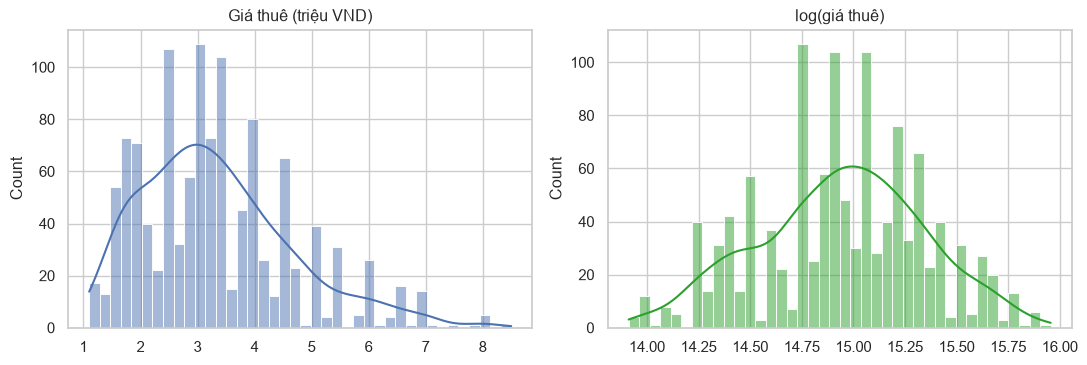

Skewness  giá gốc :  0.838
Skewness  log giá : -0.138   (gần 0 = đối xứng hơn)
Kurtosis  log giá : -0.404


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["price_vnd"] / 1e6, bins=40, kde=True, ax=ax[0]); ax[0].set(title="Giá thuê (triệu VND)", xlabel="")
sns.histplot(df[TARGET], bins=40, kde=True, ax=ax[1], color="tab:green"); ax[1].set(title="log(giá thuê)", xlabel="")
plt.tight_layout(); plt.show()

print(f"Skewness  giá gốc : {stats.skew(df.price_vnd):6.3f}")
print(f"Skewness  log giá : {stats.skew(df[TARGET]):6.3f}   (gần 0 = đối xứng hơn)")
print(f"Kurtosis  log giá : {stats.kurtosis(df[TARGET]):6.3f}")

## 4. Ma trận tương quan

- **Spearman (ρ):** đo quan hệ đơn điệu, bền với outlier → dùng làm thước đo chính.
- **Pearson (r):** đo quan hệ tuyến tính (với biến nhị phân chính là point-biserial).
- Hai mục đích: (a) biến nào liên quan tới giá; (b) **cặp biến nào tương quan quá cao** (đa cộng tuyến) → gây bất ổn hệ số ở mô hình tuyến tính.

In [5]:
# 4.1 Tương quan từng biến số / nhị phân với log_price
rows = []
for c in NUM_COLS + BIN_COLS:
    r, p_r = stats.pearsonr(df[c], df[TARGET])
    rho, p_s = stats.spearmanr(df[c], df[TARGET])
    rows.append(dict(feature=c, loai="số" if c in NUM_COLS else "nhị phân",
                     pearson_r=r, p_pearson=p_r, spearman_rho=rho, p_spearman=p_s))
corr_tbl = pd.DataFrame(rows).set_index("feature")
corr_tbl["p_spearman_adj"] = multipletests(corr_tbl["p_spearman"], method="fdr_bh")[1]
corr_tbl["abs_rho"] = corr_tbl["spearman_rho"].abs()
corr_tbl = corr_tbl.sort_values("abs_rho", ascending=False)
corr_tbl

,loai,pearson_r,p_pearson,spearman_rho,p_spearman,p_spearman_adj,abs_rho
feature,,,,,,,
size_m2,số,0.4946,0.0000,0.4982,0.0000,0.0000,0.4982
has_elevator,nhị phân,0.2764,0.0000,0.2775,0.0000,0.0000,0.2775
has_balcony,nhị phân,0.2502,0.0000,0.2505,0.0000,0.0000,0.2505
longitude,số,0.1901,0.0000,0.1876,0.0000,0.0000,0.1876
private_bathroom,nhị phân,-0.1372,0.0000,-0.1439,0.0000,0.0000,0.1439
dist_to_beach,số,-0.1545,0.0000,-0.1356,0.0000,0.0000,0.1356
has_window,nhị phân,0.1371,0.0000,0.1328,0.0000,0.0000,0.1328
has_mezzanine,nhị phân,-0.1211,0.0000,-0.1247,0.0000,0.0000,0.1247
dist_to_cbd,số,-0.1226,0.0000,-0.1134,0.0001,0.0002,0.1134


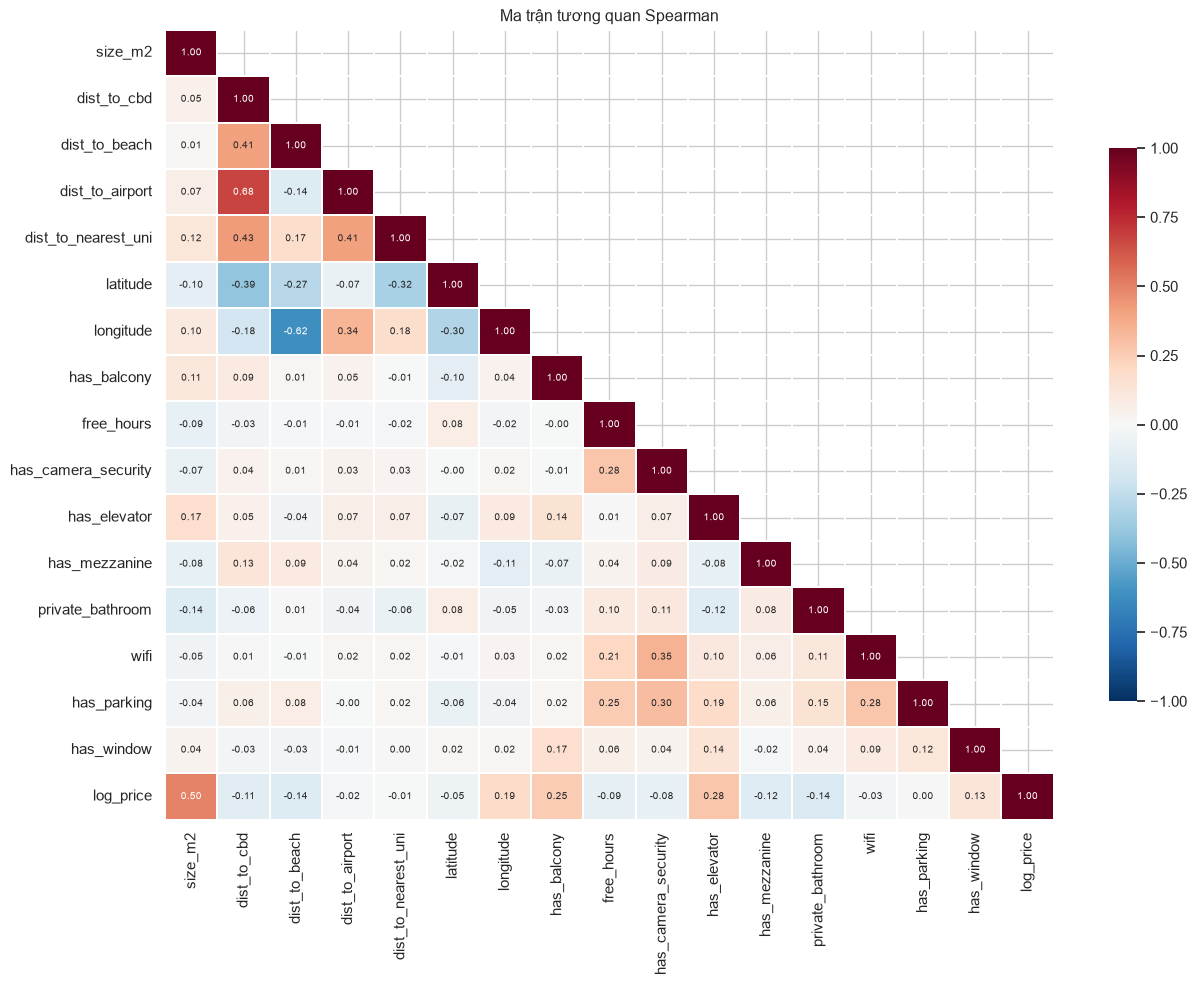

In [6]:
# 4.2 Heatmap ma trận tương quan Spearman (biến số + nhị phân + log_price)
cols = NUM_COLS + BIN_COLS + [TARGET]
C = df[cols].corr(method="spearman")
mask = np.triu(np.ones_like(C, dtype=bool), k=1)
plt.figure(figsize=(13, 10))
sns.heatmap(C, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=.3, cbar_kws={"shrink": .7})
plt.title("Ma trận tương quan Spearman"); plt.tight_layout(); plt.show()

In [7]:
# 4.3 Các cặp biến tương quan cao (nguy cơ đa cộng tuyến)
feat_cols = NUM_COLS + BIN_COLS
Cf = df[feat_cols].corr(method="spearman")
pairs = [(a, b, Cf.loc[a, b]) for i, a in enumerate(feat_cols) for b in feat_cols[i + 1:]
         if abs(Cf.loc[a, b]) >= CORR_THRESH * 0.75]          # in cả cặp "gần ngưỡng" để tham khảo
pairs = pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman_rho"])
pairs["abs"] = pairs.spearman_rho.abs()
print(f"Cặp có |ρ| >= {CORR_THRESH*0.75:.2f} (ngưỡng loại: {CORR_THRESH}):")
pairs.sort_values("abs", ascending=False).drop(columns="abs").reset_index(drop=True)

Cặp có |ρ| >= 0.60 (ngưỡng loại: 0.8):


,feature_a,feature_b,spearman_rho
0,dist_to_cbd,dist_to_airport,0.6762
1,dist_to_beach,longitude,-0.6216


In [8]:
# 4.4 VIF - Variance Inflation Factor (VIF > 5 đáng chú ý, > 10 nghiêm trọng)
Xv = sm.add_constant(df[feat_cols].astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=feat_cols, name="VIF").sort_values(ascending=False)
print("VIF (chỉ biến số + nhị phân):")
vif.to_frame()

VIF (chỉ biến số + nhị phân):


,VIF
dist_to_cbd,17.9868
longitude,10.7151
dist_to_airport,10.4705
latitude,6.9545
dist_to_beach,3.2186
dist_to_nearest_uni,1.7874
has_camera_security,1.2677
has_parking,1.2616
wifi,1.2096
free_hours,1.1467


## 5. T-test cho biến nhị phân (0/1)

Với mỗi biến nhị phân, so sánh `log(giá)` giữa nhóm **có (1)** và **không (0)**:

- **Welch t-test** (không giả định phương sai bằng nhau) → p-value chính.
- **Mann-Whitney U** → kiểm định phi tham số để đối chiếu (nếu hai kết quả mâu thuẫn, cần thận trọng).
- **Cohen's d** → độ lớn tác động (|d| ≥ 0.2 nhỏ, ≥ 0.5 vừa, ≥ 0.8 lớn).
- **% chênh lệch giá** = exp(mean₁ − mean₀) − 1 (chênh lệch giá theo trung bình nhân, dễ diễn giải).
- p-value hiệu chỉnh bằng **FDR (Benjamini-Hochberg)**.

H₀: giá trung bình (log) của hai nhóm bằng nhau.

In [9]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp if sp > 0 else np.nan

def label_effect(v, kind):
    v = abs(v)
    bins = {"d": (0.2, 0.5, 0.8), "eta2": (0.01, 0.06, 0.14), "rho": (0.1, 0.3, 0.5)}[kind]
    return ("không đáng kể", "nhỏ", "vừa", "lớn")[sum(v >= b for b in bins)]

rows = []
for c in BIN_COLS:
    g1, g0 = df.loc[df[c] == 1, TARGET], df.loc[df[c] == 0, TARGET]
    row = dict(feature=c, n_1=len(g1), n_0=len(g0))
    if min(len(g1), len(g0)) < MIN_GROUP:
        row["ghi_chu"] = f"bỏ qua (nhóm < {MIN_GROUP})"
    else:
        t, p = stats.ttest_ind(g1, g0, equal_var=False)
        _, p_mw = stats.mannwhitneyu(g1, g0, alternative="two-sided")
        d = cohens_d(g1, g0)
        row.update(mean_1=g1.mean(), mean_0=g0.mean(), pct_chenh_gia=(np.exp(g1.mean() - g0.mean()) - 1) * 100,
                   t_stat=t, p_welch=p, p_mannwhitney=p_mw, p_levene=stats.levene(g1, g0).pvalue,
                   cohens_d=d, effect=label_effect(d, "d"))
    rows.append(row)

ttest_tbl = pd.DataFrame(rows).set_index("feature")
ok = ttest_tbl["p_welch"].notna()
ttest_tbl.loc[ok, "p_welch_adj"] = multipletests(ttest_tbl.loc[ok, "p_welch"], method="fdr_bh")[1]
ttest_tbl["significant"] = ttest_tbl["p_welch_adj"] < ALPHA
ttest_tbl["abs_d"] = ttest_tbl["cohens_d"].abs()
ttest_tbl = ttest_tbl.sort_values("abs_d", ascending=False)
ttest_tbl[["n_1", "n_0", "pct_chenh_gia", "t_stat", "p_welch", "p_welch_adj", "p_mannwhitney",
           "cohens_d", "effect", "significant", "ghi_chu"]] if "ghi_chu" in ttest_tbl else ttest_tbl

,n_1,n_0,mean_1,mean_0,pct_chenh_gia,t_stat,p_welch,p_mannwhitney,p_levene,cohens_d,effect,p_welch_adj,significant,abs_d
feature,,,,,,,,,,,,,,
has_elevator,128,1062,15.2599,14.9013,43.1239,11.6822,0.0000,0.0000,0.0052,0.9276,lớn,0.0000,True,0.9276
has_balcony,167,1023,15.1887,14.8993,33.5725,10.9336,0.0000,0.0000,0.0000,0.7434,vừa,0.0000,True,0.7434
has_window,182,1008,15.0695,14.9165,16.5366,5.2408,0.0000,0.0000,0.0240,0.3841,nhỏ,0.0000,True,0.3841
private_bathroom,192,998,14.8142,14.9641,-13.9201,-5.0874,0.0000,0.0000,0.3164,-0.3763,nhỏ,0.0000,True,0.3763
has_mezzanine,283,907,14.8528,14.9671,-10.7996,-4.6889,0.0000,0.0000,0.0000,-0.2863,nhỏ,0.0000,True,0.2863
free_hours,287,903,14.8802,14.9589,-7.5619,-3.0507,0.0024,0.0014,0.0210,-0.1962,không đáng kể,0.0036,True,0.1962
has_camera_security,186,1004,14.8786,14.9512,-7.0025,-2.6136,0.0094,0.0058,0.0001,-0.1809,không đáng kể,0.0121,True,0.1809
wifi,342,848,14.9277,14.9448,-1.7011,-0.6702,0.5030,0.3292,0.8927,-0.0427,không đáng kể,0.5659,False,0.0427
has_parking,386,804,14.9421,14.9388,0.3217,0.1322,0.8949,0.9639,0.1043,0.0080,không đáng kể,0.8949,False,0.0080


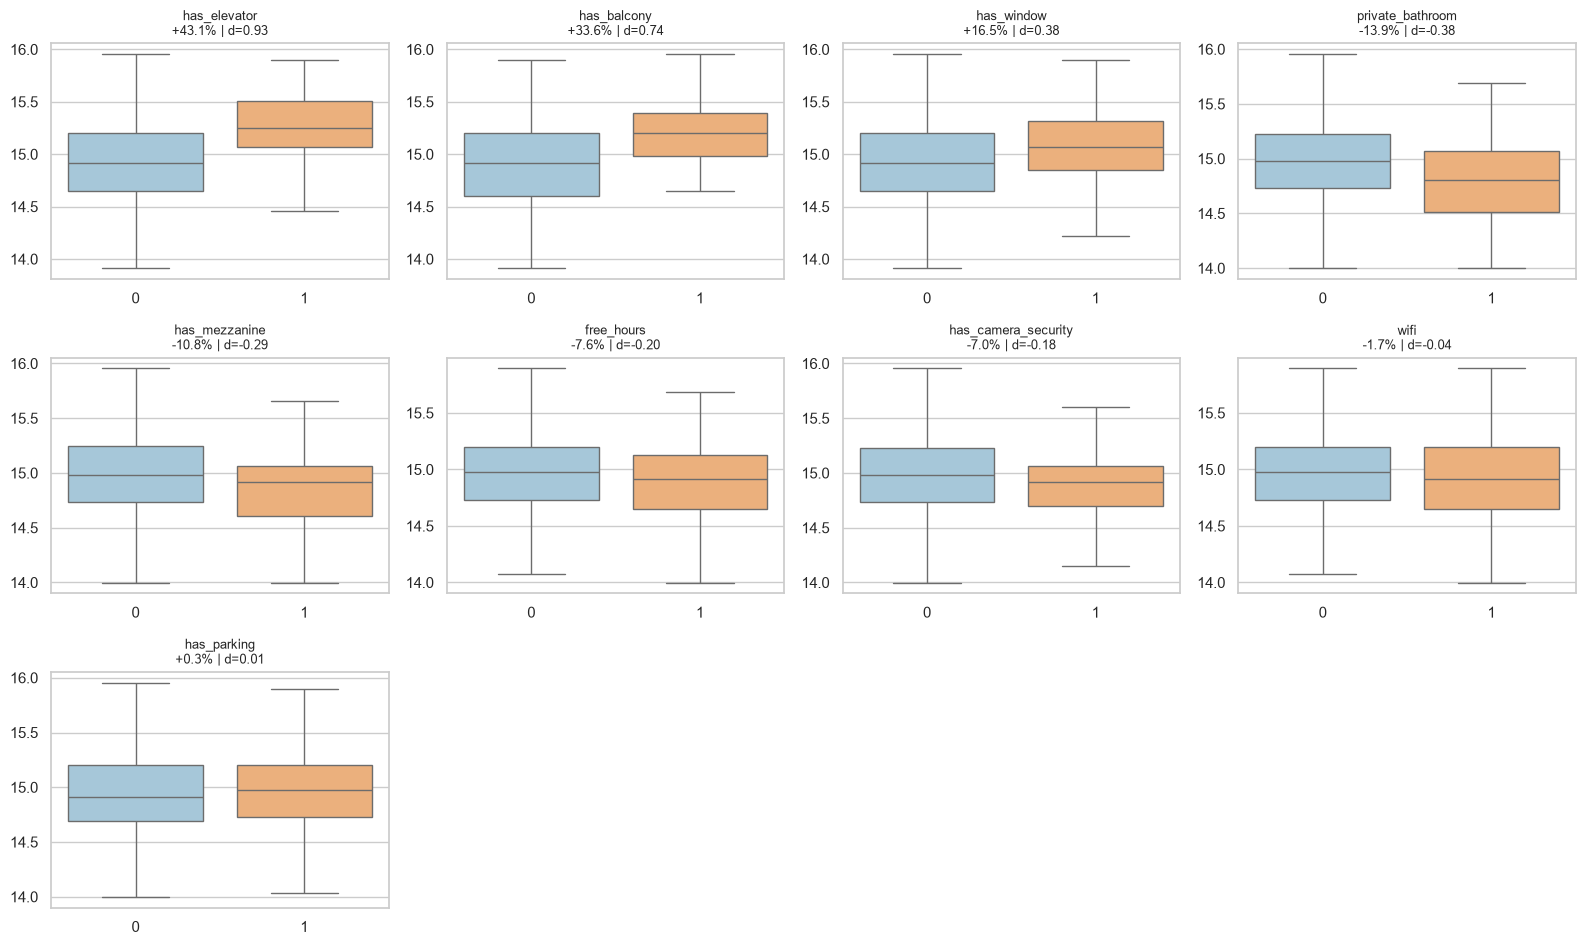

In [10]:
# Trực quan: phân phối log_price theo từng biến nhị phân (tên biến kèm % chênh lệch giá)
vis = [c for c in ttest_tbl.index if pd.notna(ttest_tbl.loc[c, "p_welch"])]
ncol = 4; nrow = int(np.ceil(len(vis) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.2 * nrow)); axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, vis):
    sns.boxplot(data=df, x=c, y=TARGET, ax=ax, palette=["#9ecae1", "#fdae6b"], showfliers=False)
    ax.set_title(f"{c}\n{ttest_tbl.loc[c,'pct_chenh_gia']:+.1f}% | d={ttest_tbl.loc[c,'cohens_d']:.2f}", fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes[len(vis):]: ax.axis("off")
plt.tight_layout(); plt.show()

## 6. ANOVA cho biến phân loại (`furnishing_status`, `ward_name`, `nearest_beach_code`, `nearest_uni_code`)

Với mỗi biến, so sánh `log(giá)` giữa ≥ 3 nhóm:

- **Levene** → kiểm tra phương sai đồng nhất (nếu p < 0.05, ưu tiên Welch-ANOVA).
- **One-way ANOVA (F)** và **Welch-ANOVA** (bền với phương sai không đều) và **Kruskal-Wallis** (phi tham số).
- **η² (eta-squared)** = tỷ lệ phương sai của log_price được giải thích bởi biến (≥ 0.01 nhỏ, ≥ 0.06 vừa, ≥ 0.14 lớn).
- **Tukey HSD** → nhóm nào khác nhóm nào (post-hoc).
- **Cramér's V** giữa các biến phân loại → phát hiện biến trùng thông tin (vd. phường ↔ bãi biển gần nhất).

H₀: giá trung bình (log) của tất cả các nhóm bằng nhau.

In [11]:
def welch_anova(groups):
    groups = [g for g in groups if g.var(ddof=1) > 0]
    k = len(groups)
    n = np.array([len(g) for g in groups]); m = np.array([g.mean() for g in groups])
    v = np.array([g.var(ddof=1) for g in groups]); w = n / v; sw = w.sum(); mw = (w * m).sum() / sw
    a = (w * (m - mw) ** 2).sum() / (k - 1)
    tmp = ((1 - w / sw) ** 2 / (n - 1)).sum()
    b = 1 + 2 * (k - 2) / (k ** 2 - 1) * tmp
    F = a / b; df2 = (k ** 2 - 1) / (3 * tmp)
    return F, stats.f.sf(F, k - 1, df2)

def eta_omega(groups):
    allv = np.concatenate(groups); gm = allv.mean(); k = len(groups); N = len(allv)
    ssb = sum(len(g) * (g.mean() - gm) ** 2 for g in groups)
    sst = ((allv - gm) ** 2).sum(); ssw = sst - ssb
    msw = ssw / (N - k)
    return ssb / sst, max((ssb - (k - 1) * msw) / (sst + msw), 0)

rows, kept_groups = [], {}
for c in CAT_COLS:
    vc = df[c].value_counts()
    keep = vc[vc >= MIN_GROUP_CAT].index
    sub = df[df[c].isin(keep)]
    groups = [g[TARGET].values for _, g in sub.groupby(c)]
    kept_groups[c] = list(keep)
    F, p = stats.f_oneway(*groups)
    Fw, pw = welch_anova(groups)
    H, pk = stats.kruskal(*groups)
    eta2, omega2 = eta_omega(groups)
    rows.append(dict(feature=c, n_nhom=len(groups), n_nhom_bi_bo=len(vc) - len(keep),
                     p_levene=stats.levene(*groups).pvalue, F=F, p_anova=p, F_welch=Fw, p_welch=pw,
                     p_kruskal=pk, eta2=eta2, omega2=omega2, effect=label_effect(eta2, "eta2")))

anova_tbl = pd.DataFrame(rows).set_index("feature")
anova_tbl["p_welch_adj"] = multipletests(anova_tbl["p_welch"], method="fdr_bh")[1]
anova_tbl["significant"] = anova_tbl["p_welch_adj"] < ALPHA
anova_tbl.sort_values("eta2", ascending=False)

,n_nhom,n_nhom_bi_bo,p_levene,F,p_anova,F_welch,p_welch,p_kruskal,eta2,omega2,effect,p_welch_adj,significant
feature,,,,,,,,,,,,,
furnishing_status,4,0,0.0009,162.2421,0.0000,154.1051,0.0000,0.0000,0.2910,0.2890,lớn,0.0000,True
nearest_uni_code,14,1,0.0223,3.7938,0.0000,4.0171,0.0000,0.0000,0.0403,0.0297,nhỏ,0.0000,True
ward_name,11,0,0.0120,4.3728,0.0000,4.3152,0.0000,0.0000,0.0358,0.0276,nhỏ,0.0000,True
nearest_beach_code,9,4,0.0178,4.9896,0.0000,4.5862,0.0001,0.0000,0.0333,0.0266,nhỏ,0.0001,True


In [12]:
# Kích thước nhóm & giá trung vị theo nhóm (nhóm quá nhỏ làm hệ số one-hot kém tin cậy)
for c in CAT_COLS:
    t = (df.groupby(c)["price_vnd"].agg(n="size", gia_trung_vi="median").sort_values("n", ascending=False))
    t["gia_trung_vi"] = t["gia_trung_vi"].map("{:,.0f}".format)
    print(f"\n--- {c} ({len(t)} nhóm) ---"); print(t.to_string())


--- furnishing_status (4 nhóm) ---
                     n gia_trung_vi
furnishing_status                  
Đầy đủ nội thất    660    3,500,000
Không nội thất     300    2,200,000
Nội thất cơ bản    178    2,500,000
Nội thất cao cấp    52    4,850,000

--- ward_name (11 nhóm) ---
                n gia_trung_vi
ward_name                     
Ngũ Hành Sơn  228    3,300,000
Hòa Cường     139    3,200,000
Hòa Khánh     136    3,000,000
Hòa Xuân      120    3,300,000
An Hải        102    3,500,000
Hải Châu       91    3,000,000
Cẩm Lệ         91    3,000,000
An Khê         87    2,800,000
Thanh Khê      74    2,800,000
Sơn Trà        63    3,000,000
Liên Chiểu     59    2,700,000

--- nearest_beach_code (13 nhóm) ---
                      n gia_trung_vi
nearest_beach_code                  
ThanhBinh           389    3,000,000
BacMyAn             206    3,350,000
SonThuy             183    3,200,000
XuanThieu           131    2,800,000
PhamVanDong          85    3,500,000
MyKhe              

In [13]:
# Tukey HSD cho furnishing_status (ít nhóm, dễ đọc)
sub = df[df["furnishing_status"].isin(kept_groups["furnishing_status"])]
tk = pairwise_tukeyhsd(sub[TARGET], sub["furnishing_status"], alpha=ALPHA)
tk_df = pd.DataFrame(tk._results_table.data[1:], columns=tk._results_table.data[0])
tk_df["chenh_lech_gia_%"] = (np.exp(tk_df["meandiff"].astype(float)) - 1) * 100
tk_df

,group1,group2,meandiff,p-adj,lower,upper,reject,chenh_lech_gia_%
0,Không nội thất,Nội thất cao cấp,0.7020,0.0000,0.5710,0.8330,True,101.7784
1,Không nội thất,Nội thất cơ bản,0.0961,0.0147,0.0136,0.1786,True,10.0869
2,Không nội thất,Đầy đủ nội thất,0.4416,0.0000,0.3809,0.5023,True,55.5194
3,Nội thất cao cấp,Nội thất cơ bản,-0.6059,0.0000,-0.7433,-0.4684,True,-45.4417
4,Nội thất cao cấp,Đầy đủ nội thất,-0.2604,0.0000,-0.3860,-0.1348,True,-22.9257
5,Nội thất cơ bản,Đầy đủ nội thất,0.3455,0.0000,0.2718,0.4191,True,41.2696


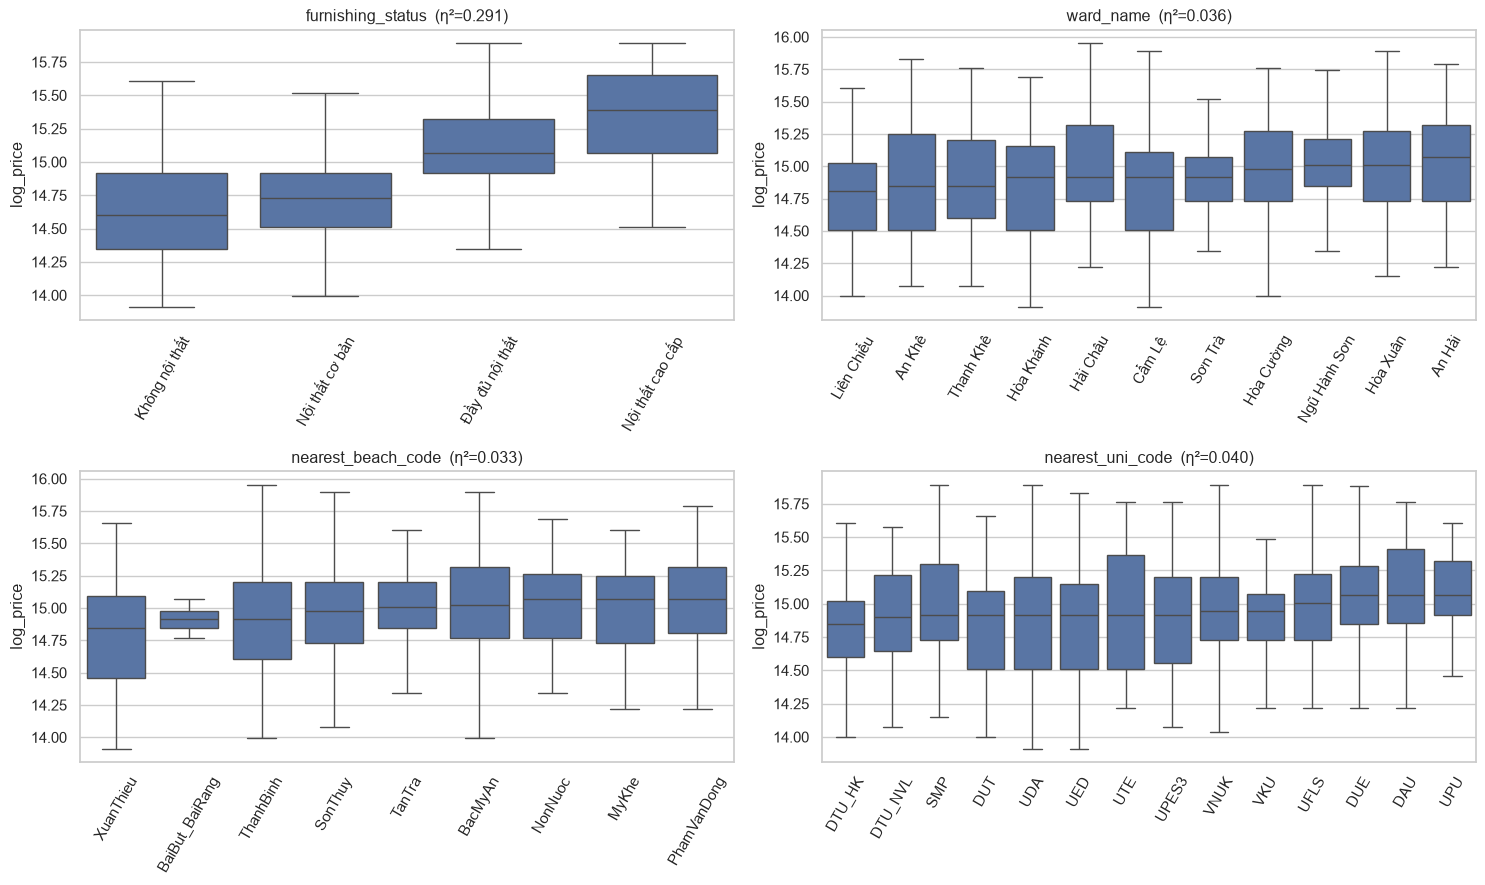

In [14]:
# Boxplot theo biến phân loại
fig, axes = plt.subplots(2, 2, figsize=(15, 9)); axes = axes.ravel()
for ax, c in zip(axes, CAT_COLS):
    order = df[df[c].isin(kept_groups[c])].groupby(c)[TARGET].median().sort_values().index
    sns.boxplot(data=df[df[c].isin(kept_groups[c])], x=c, y=TARGET, order=order, ax=ax, showfliers=False)
    ax.set_title(f"{c}  (η²={anova_tbl.loc[c,'eta2']:.3f})"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

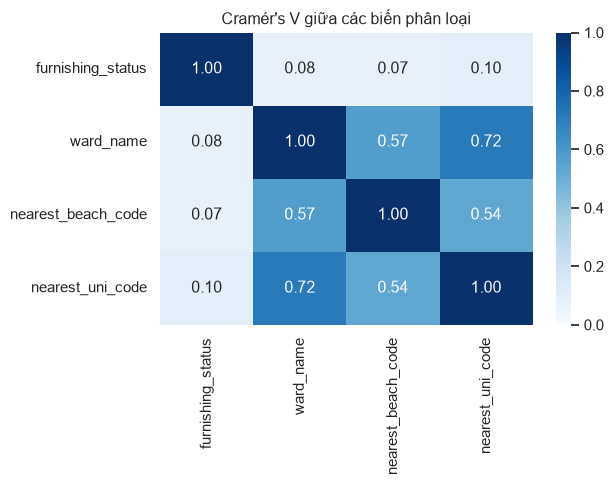

In [15]:
# Cramér's V (hiệu chỉnh sai lệch) giữa các biến phân loại -> phát hiện dư thừa thông tin
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(min(kc - 1, rc - 1), 1e-9))

V = pd.DataFrame(index=CAT_COLS, columns=CAT_COLS, dtype=float)
for a in CAT_COLS:
    for b in CAT_COLS:
        V.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])
plt.figure(figsize=(6.5, 5)); sns.heatmap(V, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cramér's V giữa các biến phân loại"); plt.tight_layout(); plt.show()

## 7. Mutual Information (bắt quan hệ phi tuyến)

Tương quan/T-test/ANOVA chỉ thấy quan hệ **đơn điệu hoặc khác biệt trung bình**. Mutual Information (MI) đo mọi dạng phụ thuộc,
nên hữu ích khi chọn feature cho mô hình **phi tuyến**.

Để biết MI bao nhiêu là "đáng kể", thêm **5 cột nhiễu ngẫu nhiên** (probe): feature nào có MI ≤ MI lớn nhất của nhiễu → coi là không mang thông tin.

> Lưu ý: MI của biến phân loại nhiều nhóm (vd. `ward_name`) có thiên lệch tăng nhẹ.

Ngưỡng nhiễu (MI lớn nhất của cột ngẫu nhiên): 0.0175


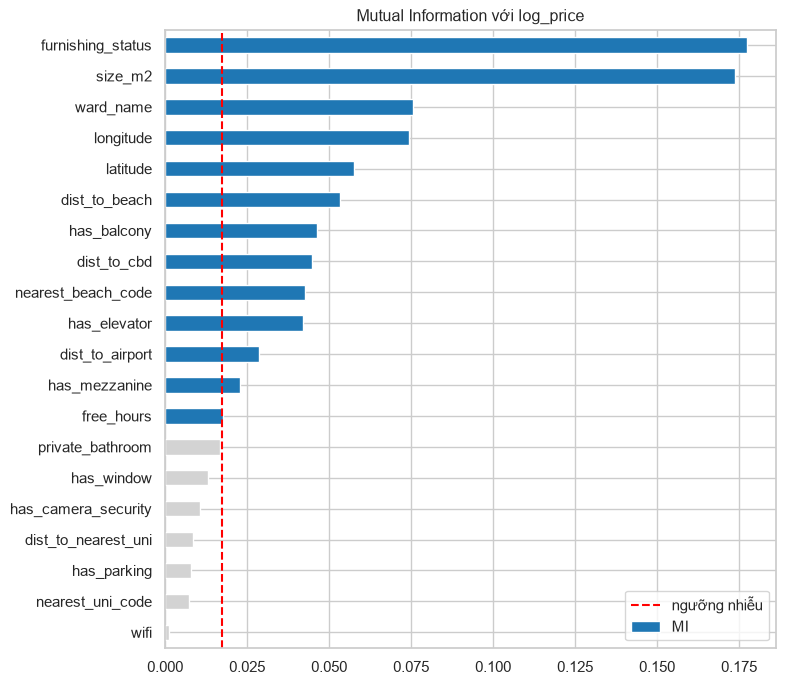

,MI,vuot_nguong_nhieu
furnishing_status,0.1773,True
size_m2,0.1738,True
ward_name,0.0756,True
longitude,0.0743,True
latitude,0.0576,True
dist_to_beach,0.0534,True
has_balcony,0.0463,True
dist_to_cbd,0.0448,True
nearest_beach_code,0.0426,True
has_elevator,0.0421,True


In [16]:
rng = np.random.default_rng(RANDOM_STATE)
Xmi = df[NUM_COLS + BIN_COLS].astype(float).copy()
for c in CAT_COLS:
    Xmi[c] = df[c].astype("category").cat.codes
for i in range(5):
    Xmi[f"__noise_{i}"] = rng.normal(size=len(df))

discrete = np.array([(c in BIN_COLS) or (c in CAT_COLS) for c in Xmi.columns])
mi = mutual_info_regression(Xmi, df[TARGET], discrete_features=discrete, n_neighbors=5, random_state=RANDOM_STATE)
mi = pd.Series(mi, index=Xmi.columns, name="MI")
MI_NOISE_THR = mi.filter(like="__noise").max()
mi_tbl = mi.drop(index=mi.filter(like="__noise").index).sort_values(ascending=False).to_frame()
mi_tbl["vuot_nguong_nhieu"] = mi_tbl["MI"] > MI_NOISE_THR
print(f"Ngưỡng nhiễu (MI lớn nhất của cột ngẫu nhiên): {MI_NOISE_THR:.4f}")

ax = mi_tbl["MI"].plot.barh(figsize=(8, 7), color=np.where(mi_tbl["vuot_nguong_nhieu"], "tab:blue", "lightgray"))
ax.axvline(MI_NOISE_THR, color="red", ls="--", label="ngưỡng nhiễu"); ax.invert_yaxis(); ax.legend()
ax.set_title("Mutual Information với log_price"); plt.tight_layout(); plt.show()
mi_tbl

## 8. Kiểm định riêng phần (Partial F-test trên OLS)

T-test/ANOVA/tương quan ở trên là **kiểm định đơn biến**: một biến có thể "có ý nghĩa" chỉ vì nó tương quan với biến khác
(vd. phòng có thang máy thường rộng hơn → giá cao do diện tích, không phải do thang máy).

Ở đây ta **kiểm soát các biến còn lại**: với mỗi feature, so sánh mô hình OLS đầy đủ với mô hình bỏ feature đó
(F-test lồng nhau; biến phân loại được kiểm định chung toàn bộ dummy).
Kết quả: **p riêng phần** và **ΔR²** = phần R² mất đi khi bỏ feature.

Trước đó, các biến số/nhị phân **dư thừa** (|ρ| ≥ ngưỡng) được cắt tỉa: giữ biến có |ρ| với giá cao hơn.

In [17]:
# 8.1 Cắt tỉa đa cộng tuyến (greedy)
target_abs = corr_tbl["abs_rho"]
def prune_collinear(features, thr=CORR_THRESH):
    keep, dropped = list(features), {}
    Cs = df[features].corr(method="spearman").abs()
    while len(keep) > 1:
        M = Cs.loc[keep, keep].to_numpy().copy(); np.fill_diagonal(M, 0)
        i, j = np.unravel_index(M.argmax(), M.shape)
        if M[i, j] < thr: break
        a, b = keep[i], keep[j]
        loser, winner = (a, b) if target_abs[a] < target_abs[b] else (b, a)
        dropped[loser] = f"{winner} (|ρ|={M[i, j]:.2f})"; keep.remove(loser)
    return keep, dropped

num_bin_kept, redundant = prune_collinear(NUM_COLS + BIN_COLS)
print("Biến bị loại vì dư thừa:", redundant or "không có")
CANDIDATES = num_bin_kept + CAT_COLS
print(f"\nSố ứng viên đưa vào OLS: {len(CANDIDATES)}")

Biến bị loại vì dư thừa: không có

Số ứng viên đưa vào OLS: 20


In [18]:
# 8.2 Partial F-test
def build_design(feats):
    parts, colmap = [], {}
    for f in feats:
        if f in CAT_COLS:
            d = pd.get_dummies(df[f].astype(str), prefix=f, drop_first=True, dtype=float)
        elif f == "size_m2":
            d = np.log(df[["size_m2"]]).rename(columns={"size_m2": "log_size_m2"})
        else:
            d = df[[f]].astype(float)
        parts.append(d); colmap[f] = list(d.columns)
    return sm.add_constant(pd.concat(parts, axis=1)), colmap

X_ols, colmap = build_design(CANDIDATES)
full = sm.OLS(df[TARGET], X_ols).fit()
print(f"OLS đầy đủ: R² = {full.rsquared:.4f} | R² hiệu chỉnh = {full.rsquared_adj:.4f} | n = {int(full.nobs)}, p = {int(full.df_model)}")

rows = []
for f in CANDIDATES:
    red = sm.OLS(df[TARGET], X_ols.drop(columns=colmap[f])).fit()
    F, p, dfd = full.compare_f_test(red)
    rows.append(dict(feature=f, df=int(dfd), F=F, p_partial=p, delta_R2=full.rsquared - red.rsquared))
partial_tbl = pd.DataFrame(rows).set_index("feature")
partial_tbl["p_partial_adj"] = multipletests(partial_tbl["p_partial"], method="fdr_bh")[1]
partial_tbl["significant"] = partial_tbl["p_partial_adj"] < PARTIAL_ALPHA
partial_tbl.sort_values("delta_R2", ascending=False)

OLS đầy đủ: R² = 0.5382 | R² hiệu chỉnh = 0.5158 | n = 1190, p = 55


,df,F,p_partial,delta_R2,p_partial_adj,significant
feature,,,,,,
furnishing_status,3,105.7537,0.0000,0.1292,0.0000,True
size_m2,1,284.0474,0.0000,0.1157,0.0000,True
has_elevator,1,28.0061,0.0000,0.0114,0.0000,True
has_balcony,1,25.6731,0.0000,0.0105,0.0000,True
nearest_beach_code,12,2.0947,0.0150,0.0102,0.0332,True
ward_name,10,1.7628,0.0630,0.0072,0.1259,False
nearest_uni_code,14,1.1867,0.2792,0.0068,0.3490,False
free_hours,1,7.9051,0.0050,0.0032,0.0201,True
wifi,1,7.3649,0.0068,0.0030,0.0225,True


## 9. Tổng hợp & quyết định chọn feature

**Quy tắc (có thể chỉnh ở phần cấu hình):**

| | Điều kiện |
|---|---|
| **Loại hẳn** | Cột hằng số, cột rò rỉ nhãn |
| **Mô hình tuyến tính** | *Giữ* nếu **p riêng phần (FDR) < `PARTIAL_ALPHA` (0.10)** *và* không bị loại do đa cộng tuyến |
| **Mô hình phi tuyến (cây)** | *Giữ* nếu (đơn biến có ý nghĩa **và** effect ≥ ngưỡng nhỏ) **hoặc** p riêng phần < α **hoặc** MI vượt ngưỡng nhiễu. Cây chịu được đa cộng tuyến nên không cắt tỉa theo tương quan |

In [19]:
all_feats = NUM_COLS + BIN_COLS + CAT_COLS
S = pd.DataFrame(index=all_feats)
S["loai"] = ["số" if f in NUM_COLS else "nhị phân" if f in BIN_COLS else "phân loại" for f in S.index]

# --- đơn biến: p (FDR) + effect size
S["p_univar_adj"] = np.nan; S["effect"] = np.nan; S["effect_type"] = ""
for f in S.index:
    if f in NUM_COLS:
        S.loc[f, ["p_univar_adj", "effect", "effect_type"]] = [corr_tbl.loc[f, "p_spearman_adj"], corr_tbl.loc[f, "abs_rho"], "|rho|"]
    elif f in BIN_COLS and f in ttest_tbl.index and pd.notna(ttest_tbl.loc[f, "p_welch_adj"]):
        S.loc[f, ["p_univar_adj", "effect", "effect_type"]] = [ttest_tbl.loc[f, "p_welch_adj"], ttest_tbl.loc[f, "abs_d"], "|d|"]
    elif f in CAT_COLS:
        S.loc[f, ["p_univar_adj", "effect", "effect_type"]] = [anova_tbl.loc[f, "p_welch_adj"], anova_tbl.loc[f, "eta2"], "eta2"]
S["effect"] = S["effect"].astype(float)

thr_map = {"|rho|": MIN_EFFECT["rho"], "|d|": MIN_EFFECT["d"], "eta2": MIN_EFFECT["eta2"]}
S["uni_sig"] = S["p_univar_adj"] < ALPHA
S["effect_ok"] = [(e >= thr_map[t]) if t else False for e, t in zip(S["effect"], S["effect_type"])]

# --- MI, partial, VIF, dư thừa
S["MI"] = mi_tbl["MI"]; S["mi_ok"] = mi_tbl["vuot_nguong_nhieu"].reindex(S.index).fillna(False).astype(bool)
S["p_partial_adj"] = partial_tbl["p_partial_adj"]; S["delta_R2"] = partial_tbl["delta_R2"]
S["partial_sig"] = (S["p_partial_adj"] < PARTIAL_ALPHA).fillna(False)
S["VIF"] = vif
S["du_thua_voi"] = pd.Series(redundant)

# --- quyết định
S["keep_linear"]    = S["partial_sig"] & S["du_thua_voi"].isna()
S["keep_nonlinear"] = (S["uni_sig"] & S["effect_ok"]) | S["partial_sig"] | S["mi_ok"]

def reason(r):
    out = []
    if pd.notna(r["du_thua_voi"]): out.append(f"dư thừa với {r['du_thua_voi']}")
    if not r["partial_sig"] and pd.isna(r["du_thua_voi"]): out.append("không có ý nghĩa riêng phần")
    if r["uni_sig"] and not r["effect_ok"]: out.append("có ý nghĩa nhưng effect quá nhỏ")
    if r["partial_sig"] and not r["uni_sig"] and not r["mi_ok"]: out.append("chỉ có ý nghĩa khi kiểm soát biến khác (đơn biến & MI đều yếu) - nên kiểm tra lại")
    if pd.notna(r["VIF"]) and r["VIF"] > 10: out.append(f"VIF cao ({r['VIF']:.0f}) - đa cộng tuyến đa biến")
    return "; ".join(out)
S["ghi_chu"] = S.apply(reason, axis=1)

for c in CONSTANT:
    S.loc[c] = {"loai": "hằng số", "keep_linear": False, "keep_nonlinear": False, "ghi_chu": "hằng số - loại"}
S[["keep_linear", "keep_nonlinear"]] = S[["keep_linear", "keep_nonlinear"]].fillna(False).astype(bool)

S = S.sort_values(["keep_linear", "keep_nonlinear", "delta_R2"], ascending=False)
S[["loai", "effect_type", "effect", "p_univar_adj", "MI", "mi_ok", "delta_R2", "p_partial_adj",
   "VIF", "keep_linear", "keep_nonlinear", "ghi_chu"]]

,loai,effect_type,effect,p_univar_adj,MI,mi_ok,delta_R2,p_partial_adj,VIF,keep_linear,keep_nonlinear,ghi_chu
furnishing_status,phân loại,eta2,0.2910,0.0000,0.1773,True,0.1292,0.0000,NaN,True,True,
size_m2,số,|rho|,0.4982,0.0000,0.1738,True,0.1157,0.0000,1.0868,True,True,
has_elevator,nhị phân,|d|,0.9276,0.0000,0.0421,True,0.0114,0.0000,1.1400,True,True,
has_balcony,nhị phân,|d|,0.7434,0.0000,0.0463,True,0.0105,0.0000,1.0865,True,True,
nearest_beach_code,phân loại,eta2,0.0333,0.0001,0.0426,True,0.0102,0.0332,NaN,True,True,
free_hours,nhị phân,|d|,0.1962,0.0036,0.0178,True,0.0032,0.0201,1.1467,True,True,có ý nghĩa nhưng effect quá nhỏ
wifi,nhị phân,|d|,0.0427,0.5659,0.0011,False,0.0030,0.0225,1.2096,True,True,chỉ có ý nghĩa khi kiểm soát biến khác (đơn bi...
private_bathroom,nhị phân,|d|,0.3763,0.0000,0.0168,False,0.0025,0.0332,1.0825,True,True,
dist_to_nearest_uni,số,|rho|,0.0077,0.8443,0.0085,False,0.0025,0.0332,1.7874,True,True,chỉ có ý nghĩa khi kiểm soát biến khác (đơn bi...
ward_name,phân loại,eta2,0.0358,0.0000,0.0756,True,0.0072,0.1259,NaN,False,True,không có ý nghĩa riêng phần


In [20]:
SELECTED_LINEAR    = S.index[S.keep_linear].tolist()
SELECTED_NONLINEAR = S.index[S.keep_nonlinear].tolist()
DROPPED_BOTH       = S.index[~S.keep_linear & ~S.keep_nonlinear].tolist()

print(f"SELECTED_LINEAR    ({len(SELECTED_LINEAR)}): {SELECTED_LINEAR}\n")
print(f"SELECTED_NONLINEAR ({len(SELECTED_NONLINEAR)}): {SELECTED_NONLINEAR}\n")
print(f"Loại ở cả hai ({len(DROPPED_BOTH)}): {DROPPED_BOTH}")

out_csv = f"feature_selection_summary_{'tro' if CATEGORY == 'Phòng trọ' else 'canho'}.csv"
S.to_csv(out_csv, encoding="utf-8-sig"); print(f"\nĐã lưu: {out_csv}")

SELECTED_LINEAR    (9): ['furnishing_status', 'size_m2', 'has_elevator', 'has_balcony', 'nearest_beach_code', 'free_hours', 'wifi', 'private_bathroom', 'dist_to_nearest_uni']

SELECTED_NONLINEAR (18): ['furnishing_status', 'size_m2', 'has_elevator', 'has_balcony', 'nearest_beach_code', 'free_hours', 'wifi', 'private_bathroom', 'dist_to_nearest_uni', 'ward_name', 'nearest_uni_code', 'latitude', 'has_window', 'dist_to_airport', 'longitude', 'dist_to_beach', 'dist_to_cbd', 'has_mezzanine']

Loại ở cả hai (6): ['has_camera_security', 'has_parking', 'rooms', 'flooded_2022', 'flooded_2025', 'flood_risk_label']

Đã lưu: feature_selection_summary_tro.csv


## 10. Kiểm chứng bằng cross-validation

So sánh R² (thang log giá) giữa **toàn bộ feature** và **feature đã chọn**:
- Tuyến tính: Ridge (one-hot + chuẩn hoá).
- Phi tuyến: HistGradientBoosting (biến phân loại native).

Kỳ vọng: bộ feature chọn lọc cho R² **tương đương** (hoặc nhỉnh hơn) bộ đầy đủ với ít biến hơn.

> ⚠️ Việc chọn feature ở trên dùng toàn bộ dữ liệu nên CV ở đây hơi lạc quan. Sự khác biệt giữa hai bộ feature vẫn là thước đo so sánh hợp lý;
> để chặt chẽ hơn, hãy đưa bước chọn feature vào trong từng fold.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer

def split_types(feats):
    return ([f for f in feats if f in NUM_COLS + BIN_COLS], [f for f in feats if f in CAT_COLS])

def ridge_pipe(feats):
    num, cat = split_types(feats)
    tf = []
    if "size_m2" in num:
        tf.append(("logsize", Pipeline([("log", FunctionTransformer(np.log)), ("sc", StandardScaler())]), ["size_m2"]))
        num = [c for c in num if c != "size_m2"]
    if num: tf.append(("num", StandardScaler(), num))
    if cat: tf.append(("cat", OneHotEncoder(drop="first", handle_unknown="infrequent_if_exist", min_frequency=10), cat))
    return Pipeline([("prep", ColumnTransformer(tf)), ("m", RidgeCV(alphas=np.logspace(-3, 3, 25)))])

def hgb_pipe(feats):
    num, cat = split_types(feats)
    tf = [("num", "passthrough", num)] if num else []
    if cat: tf.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), cat))
    mask = [False] * len(num) + [True] * len(cat)
    return Pipeline([("prep", ColumnTransformer(tf)),
                     ("m", HistGradientBoostingRegressor(categorical_features=mask, learning_rate=0.05, max_iter=300,
                                                         max_leaf_nodes=8, min_samples_leaf=20, l2_regularization=1.0,
                                                         random_state=RANDOM_STATE))])

cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
ALL_FEATS = NUM_COLS + BIN_COLS + CAT_COLS
experiments = {
    "Ridge  | tất cả feature":          (ridge_pipe, ALL_FEATS),
    "Ridge  | feature chọn (linear)":   (ridge_pipe, SELECTED_LINEAR),
    "HGB    | tất cả feature":          (hgb_pipe,   ALL_FEATS),
    "HGB    | feature chọn (nonlinear)": (hgb_pipe,  SELECTED_NONLINEAR),
}
rows = []
for name, (mk, feats) in experiments.items():
    sc = cross_val_score(mk(feats), df[feats], df[TARGET], cv=cv, scoring="r2", n_jobs=-1)
    rows.append(dict(thiet_lap=name, n_feature=len(feats), R2_mean=sc.mean(), R2_std=sc.std()))
pd.DataFrame(rows).set_index("thiet_lap")

,n_feature,R2_mean,R2_std
thiet_lap,,,
Ridge | tất cả feature,20,0.4942,0.0346
Ridge | feature chọn (linear),9,0.4825,0.0265
HGB | tất cả feature,20,0.5022,0.0388
HGB | feature chọn (nonlinear),18,0.5021,0.0375


## 11. Cách đọc kết quả & lưu ý

1. **Ưu tiên effect size hơn p-value.** Dữ liệu lớn khiến gần như mọi p < 0.05; hãy nhìn `cohens_d`, `eta2`, `delta_R2`.
2. **Đơn biến ≠ riêng phần.** Biến có ý nghĩa ở T-test nhưng mất ý nghĩa ở partial F-test thường là *biến đại diện* cho biến khác (vd. diện tích, phường).
3. **Phường / bãi biển / trường ĐH thường trùng thông tin** (xem Cramér's V và khoảng cách) — với mô hình tuyến tính nên giữ biến mang nhiều thông tin nhất; mô hình cây xử lý tốt hơn.
4. **Nhóm quá nhỏ** (`n < MIN_GROUP`) bị bỏ khỏi T-test: nên gộp hoặc loại thay vì kết luận.
5. **Chạy lại cho từng loại hình**: đổi `CATEGORY` ở ô cấu hình (Phòng trọ / Căn hộ/Chung cư) vì quan hệ giá–feature khác nhau giữa hai loại.
6. Các kiểm định giả định quan sát độc lập; tin đăng gần vị trí/giá tương tự có thể tương quan không gian nên p-value có phần lạc quan.